# CNNs — Version 0: Instructor live demonstration

**IMT · Introduction to Machine Learning · Google Colab**

**Purpose:** follow a complete example together **before** attempting the student labs. Every code cell is already solved so the instructor can run, change, and explain it live.

**Today we will:** (1) inspect an image dataset, (2) see a convolution work, (3) build a tiny CNN, (4) and train it.

## 1 — What does a computer see?

Each handwritten digit is an **8 × 8 grayscale image**. Pixel values are numbers; labels are the digits **0–9**.

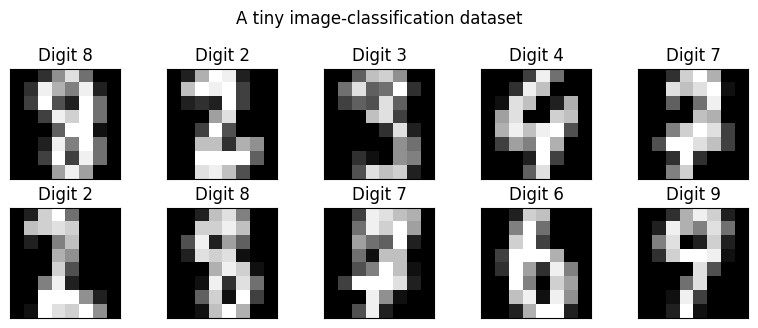

Batch input shape: (4, 1, 8, 8) (batch, channels, height, width)


In [8]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay

SEED = 7
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(2)

digits = load_digits()                         # Included in scikit-learn; no download
X = digits.images.astype("float32") / 16.0  # Intensities in [0, 1]
y = digits.target.astype("int64")
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=SEED
)
xtr = torch.tensor(X_train[:, None, :, :])  # (N, channels=1, 8, 8)
xte = torch.tensor(X_test[:, None, :, :])
ytr = torch.tensor(y_train, dtype=torch.long)
yte = torch.tensor(y_test, dtype=torch.long)
train_loader = DataLoader(TensorDataset(xtr, ytr), batch_size=64, shuffle=True)

fig, axes = plt.subplots(2, 5, figsize=(8, 3.3))
for ax, img, label in zip(axes.flat, X_train[:10], y_train[:10]):
    ax.imshow(img, cmap="gray", vmin=0, vmax=1)
    ax.set(title=f"Digit {label}", xticks=[], yticks=[])
plt.suptitle("A tiny image-classification dataset")
plt.tight_layout()
plt.show()
print("Batch input shape:", tuple(xtr[:4].shape), "(batch, channels, height, width)")

## 2 — Apply one convolution filter by hand

A **3 × 3 vertical-edge detector** looks for left-to-right intensity changes:

```text
-1   0  +1
-1   0  +1
-1   0  +1
```

We apply the same small set of weights at every location. With `padding=1`, the resulting feature map remains **8 × 8**.

**Ask the class:** Why does the filter have a shape of `(1, 1, 3, 3)`? What would happen with `padding=0`?

Input shape: (1, 1, 8, 8)
Output shape: (1, 1, 8, 8)
Value at (3, 3): manual = 0.6875 ; conv2d = 0.6875


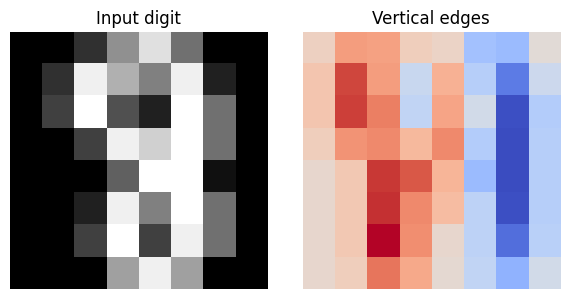

In [9]:
edge_kernel = torch.tensor([
    [-1., 0., 1.],
    [-1., 0., 1.],
    [-1., 0., 1.],
]).reshape(1, 1, 3, 3)

edge_map = F.conv2d(xtr[:1], edge_kernel, padding=1)
print("Input shape:", tuple(xtr[:1].shape))
print("Output shape:", tuple(edge_map.shape))

# Inspect one central position: libraries implement cross-correlation.
patch = xtr[0, 0, 2:5, 2:5]
manual_value = (patch * edge_kernel[0, 0]).sum().item()
print("Value at (3, 3): manual =", round(manual_value, 4),
      "; conv2d =", round(edge_map[0, 0, 3, 3].item(), 4))

fig, axes = plt.subplots(1, 2, figsize=(6, 3))
axes[0].imshow(xtr[0, 0], cmap="gray", vmin=0, vmax=1)
axes[0].set_title("Input digit")
axes[1].imshow(edge_map[0, 0], cmap="coolwarm")
axes[1].set_title("Vertical edges")
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()

## 3 — Assemble a *tiny* CNN

To make the first demonstration simple, use **one convolution block**:

```text
Input:         1 × 8 × 8
Conv2d + ReLU 8 × 8 × 8
MaxPool2d(2): 8 × 4 × 4
Flatten:      128 numbers
Linear:       10 logits (one score per digit)
```

**Ask the class:** What does pooling change? Why **10** final outputs? Why do we **not** apply softmax before `CrossEntropyLoss`?

In [10]:
model = nn.Sequential(
    nn.Conv2d(in_channels=1, out_channels=8, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size=2),
    nn.Flatten(),
    nn.Linear(8 * 4 * 4, 10),
)

example = xtr[:4]
for layer in model:
    example = layer(example)
    print(f"{layer.__class__.__name__:>12}: {tuple(example.shape)}")
print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))

      Conv2d: (4, 8, 8, 8)
        ReLU: (4, 8, 8, 8)
   MaxPool2d: (4, 8, 4, 4)
     Flatten: (4, 128)
      Linear: (4, 10)
Trainable parameters: 1370


## 4 — Train the CNN

The labels are integers **0–9**. `CrossEntropyLoss` compares the 10 raw class scores (**logits**) with the correct digit.

The five steps for each batch are: **zero gradients → predict → compute loss → backpropagate → update weights**.

**Ask the class:** Which parts of the network learn during training?

Epoch 01 | training loss 2.0512
Epoch 02 | training loss 1.3517
Epoch 03 | training loss 0.7212
Epoch 04 | training loss 0.4447
Epoch 05 | training loss 0.3162
Epoch 06 | training loss 0.2703
Epoch 07 | training loss 0.2512
Epoch 08 | training loss 0.2047
Epoch 09 | training loss 0.1881
Epoch 10 | training loss 0.1949
Epoch 11 | training loss 0.1482
Epoch 12 | training loss 0.1411


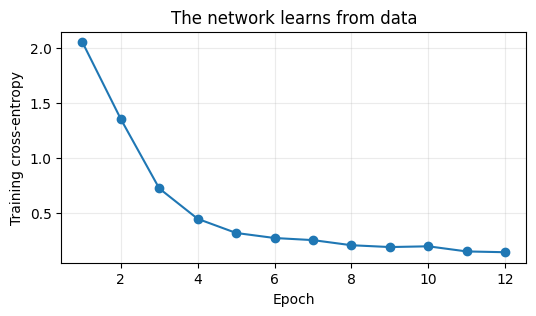

In [11]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.005)

losses = []
for epoch in range(12):
    model.train()
    running_loss = 0.0
    for xb, yb in train_loader:
        optimizer.zero_grad()
        logits = model(xb)
        loss = loss_fn(logits, yb)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * len(xb)
    average_loss = running_loss / len(train_loader.dataset)
    losses.append(average_loss)
    print(f"Epoch {epoch+1:02d} | training loss {average_loss:.4f}")

plt.figure(figsize=(6, 3))
plt.plot(range(1, 13), losses, marker="o")
plt.xlabel("Epoch"); plt.ylabel("Training cross-entropy")
plt.title("The network learns from data")
plt.grid(alpha=0.25); plt.show()

## 5 — Is it actually learning to classify?

Accuracy should be calculated on **test images never used for training**. A confusion matrix reveals *which* digits the network mixes up.

**Ask the class:** Why is training accuracy not enough?

Test accuracy: 96.9%


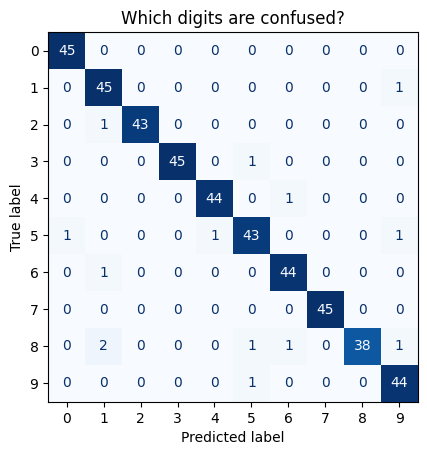

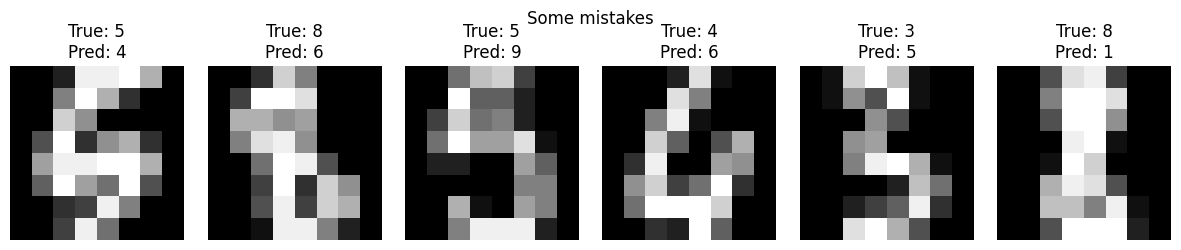

In [12]:
model.eval()
with torch.no_grad():
    logits = model(xte)
    predicted_digits = logits.argmax(dim=1).numpy()

test_acc = accuracy_score(y_test, predicted_digits)
print(f"Test accuracy: {test_acc:.1%}")
ConfusionMatrixDisplay.from_predictions(y_test, predicted_digits, cmap="Blues", colorbar=False)
plt.title("Which digits are confused?")
plt.show()

mistakes = np.flatnonzero(predicted_digits != y_test)
if len(mistakes):
    idx = mistakes[:min(6, len(mistakes))]
    fig, axs = plt.subplots(1, len(idx), figsize=(2 * len(idx), 2.5))
    axs = np.atleast_1d(axs)
    for ax, i in zip(axs, idx):
        ax.imshow(X_test[i], cmap="gray", vmin=0, vmax=1)
        ax.set_title(f"True: {y_test[i]}\nPred: {predicted_digits[i]}")
        ax.axis("off")
    plt.suptitle("Some mistakes"); plt.tight_layout(); plt.show()

## 6 — Look inside: learned feature maps

Each of the first layer's **8 filters** produces its own image. Those filters are *learned*, unlike the fixed edge detector from section 2.

**Ask the class:** Why might two learned filters respond to different strokes of the same digit?

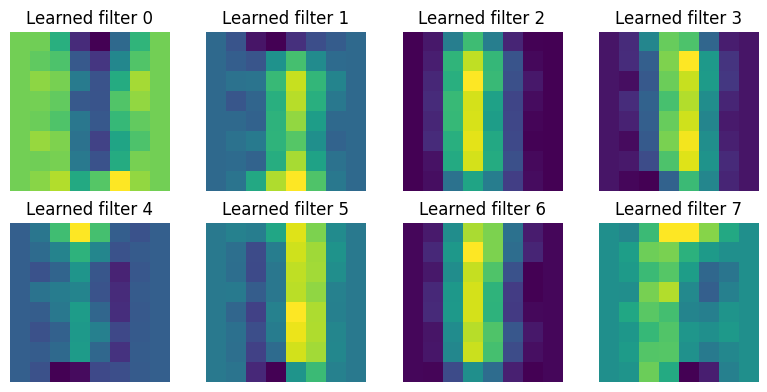

In [13]:
first_conv = model[0]
with torch.no_grad():
    feature_maps = first_conv(xte[:1])

fig, axes = plt.subplots(2, 4, figsize=(8, 4))
for k, ax in enumerate(axes.flat):
    ax.imshow(feature_maps[0, k], cmap="viridis")
    ax.set_title(f"Learned filter {k}")
    ax.axis("off")
plt.tight_layout(); plt.show()